In [1]:
from pathlib import Path
import sys,json,hashlib,importlib.util
ROOT=Path("/home/featurize/work/biological_prior_validation").resolve()
INPUT_REPORT=ROOT/"results/summary/task2_three_comparisons_v1_review_bundle.zip"
RUN=ROOT/"data/splits/step2_q05_seed20261008_v1"
METADATA_PATH=RUN/"A_preprocessing/evaluation_cells.parquet"
ANALYSIS_NAME="task2_context_reproducibility_v1"
NEAR_ZERO_PERCENT=1e-5
SENSITIVITY_BANDS=(0.,1e-5,.001,.01,.1)
if not ROOT.is_dir():raise FileNotFoundError(f"Please modify the ROOT：{ROOT}")
if not INPUT_REPORT.is_file():raise FileNotFoundError(f"Missing complete 2.3 verification package：{INPUT_REPORT}")


In [2]:
SOURCE = '"""Task 2.5: descriptive context dependence; biological directions remain blocked."""\nfrom pathlib import Path\nimport hashlib,json,zipfile,io,sys,subprocess\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nfrom matplotlib.lines import Line2D\nfrom matplotlib.ticker import MaxNLocator\nENGINE_SHA=hashlib.sha256(Path(__file__).read_bytes()).hexdigest()\nMETRICS=[\'mean_poisson_deviance\',\'normalized_mse\']\nCOLORS={\'both_better\':\'#207f88\',\'both_worse\':\'#c65e47\',\'sign_reversal\':\'#8b68a6\',\'near_zero_one_or_both\':\'#87918d\'}\ndef sha(path):\n h=hashlib.sha256()\n with Path(path).open(\'rb\') as f:\n  for b in iter(lambda:f.read(1024*1024),b\'\'):h.update(b)\n return h.hexdigest()\ndef js_bytes(o):return (json.dumps(o,ensure_ascii=False,indent=2,allow_nan=False)+\'\\n\').encode()\ndef immutable(path,data):\n path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)\n if path.exists() and path.read_bytes()!=data:raise ValueError(\'Output changed; use a new analysis name: \'+str(path))\n if not path.exists():path.write_bytes(data)\ndef classify(x,y,eps):\n if not np.isfinite([x,y,eps]).all() or eps<0:raise ValueError(\'Invalid effect/threshold\')\n if abs(x)<=eps or abs(y)<=eps:return \'near_zero_one_or_both\'\n if x<0 and y<0:return \'both_better\'\n if x>0 and y>0:return \'both_worse\'\n return \'sign_reversal\'\ndef correlations(x,y):\n x=np.asarray(x,float);y=np.asarray(y,float);keep=np.isfinite(x)&np.isfinite(y);x=x[keep];y=y[keep]\n if len(x)<3 or np.ptp(x)==0 or np.ptp(y)==0:return len(x),np.nan,np.nan\n return len(x),float(np.corrcoef(x,y)[0,1]),float(pd.Series(x).rank().corr(pd.Series(y).rank()))\ndef load_report(path):\n with zipfile.ZipFile(path) as z:\n  if z.testzip() is not None or len(set(z.namelist()))!=len(z.namelist()):raise ValueError(\'Invalid ZIP\')\n  prefix=\'results/summary/task2_three_comparisons_v1/\'\n  manifest=json.loads(z.read(prefix+\'report_manifest.json\'))\n  for f in manifest[\'files\']:\n   if hashlib.sha256(z.read(f[\'name\'])).hexdigest()!=f[\'sha256\']:raise ValueError(\'Report manifest changed: \'+f[\'name\'])\n  cfg=json.loads(z.read(\'configs/task2_three_comparisons_v1/report_contract.json\'))\n  if hashlib.sha256(z.read(\'src/task2_reporting.py\')).hexdigest()!=cfg[\'report_engine_sha256\']:raise ValueError(\'Report source mismatch\')\n  summary=json.loads(z.read(prefix+\'summary.json\'))\n  if summary[\'status\']!=\'COMPLETE\' or summary[\'n_score_rows\']!=1290 or summary[\'scenario_B\']!=\'BLOCKED\':raise ValueError(\'Wrong source/scenario\')\n  effects=pd.read_csv(io.BytesIO(z.read(prefix+\'fixed_adaptive_effects.csv\')))\n  raw=pd.read_csv(io.BytesIO(z.read(\'results/raw/task2_three_comparisons_v1/all15_complete_benchmark.csv\')))\n  return effects,raw,cfg\n\ndef effect_points(effects,near_zero_percent=1e-5):\n required=[\'cell_line\',\'drug\',\'replicate\',\'comparison\',\'metric\',\'score\',\'reference_score\',\'delta_absolute\',\'delta_percent\']\n if effects[required].isna().any().any() or len(effects)!=120:raise ValueError(\'Complete finite effects required\')\n if set(effects.comparison)!={\'fixed\',\'adaptive\'} or set(effects.metric)!=set(METRICS):raise ValueError(\'Unexpected comparisons/metrics\')\n if not np.isfinite(effects[[\'score\',\'reference_score\',\'delta_absolute\',\'delta_percent\']].to_numpy(float)).all() or not effects.reference_score.gt(0).all():raise ValueError(\'Undefined relative effects\')\n if not np.allclose(effects.delta_absolute,effects.score-effects.reference_score,rtol=1e-10,atol=1e-14):raise ValueError(\'Delta subtraction mismatch\')\n if not np.allclose(effects.delta_percent,100*effects.delta_absolute/effects.reference_score,rtol=1e-10,atol=1e-12):raise ValueError(\'Percent denominator mismatch\')\n if not np.isfinite(near_zero_percent) or near_zero_percent<0:raise ValueError(\'Invalid band\')\n contexts=sorted(set(zip(effects.cell_line,effects.drug)));ids={c:i+1 for i,c in enumerate(contexts)}\n if len(contexts)!=15:raise ValueError(\'All 15 contexts required\')\n records=[]\n for (line,drug,metric,comparison),g in effects.groupby([\'cell_line\',\'drug\',\'metric\',\'comparison\'],sort=True):\n  if len(g)!=2 or set(g.replicate)!={\'replicate_1\',\'replicate_2\'}:raise ValueError(\'Expected two labels; no fabricated directions\')\n  a=g[g.replicate.eq(\'replicate_1\')].iloc[0];b=g[g.replicate.eq(\'replicate_2\')].iloc[0]\n  x=float(a.delta_percent);y=float(b.delta_percent)\n  records.append({\'context_id\':ids[(line,drug)],\'cell_line\':line,\'drug\':drug,\'metric\':metric,\'comparison\':comparison,\'delta_label_1\':a.delta_absolute,\'delta_label_2\':b.delta_absolute,\'percent_label_1\':x,\'percent_label_2\':y,\'reference_score_label_1\':a.reference_score,\'reference_score_label_2\':b.reference_score,\'score_label_1\':a.score,\'score_label_2\':b.score,\'raw_sign_class\':classify(x,y,0.),\'near_zero_percent\':near_zero_percent,\'band_class\':classify(x,y,near_zero_percent),\'absolute_percent_gap\':abs(x-y),\'direction_validity\':\'label sensitivity only; biological directions blocked\'})\n return pd.DataFrame(records)\n\ndef distribution_metrics(counts,label1=\'replicate_1\',label2=\'replicate_2\'):\n a=counts[counts.replicate.eq(label1)].set_index(\'category\').n_cells;b=counts[counts.replicate.eq(label2)].set_index(\'category\').n_cells\n labels=a.index.union(b.index);a=a.reindex(labels,fill_value=0).to_numpy(float);b=b.reindex(labels,fill_value=0).to_numpy(float)\n if min(a.sum(),b.sum())<=0:return np.nan,np.nan\n p=a/a.sum();q=b/b.sum();m=(p+q)/2\n def kl(x):\n  keep=x>0;return float(np.sum(x[keep]*np.log2(x[keep]/m[keep])))\n return float(.5*np.abs(p-q).sum()),float(.5*(kl(p)+kl(q)))\ndef composition(metadata,roster):\n counts=[];summary=[]\n wanted=roster[[\'cell_line\',\'drug\',\'replicate\',\'n_cells\']].drop_duplicates()\n if wanted.duplicated([\'cell_line\',\'drug\',\'replicate\']).any():raise ValueError(\'Conflicting roster\')\n if len(wanted)!=30:raise ValueError(\'Full composition roster required\')\n if metadata is None:\n  return pd.DataFrame(columns=[\'cell_line\',\'drug\',\'replicate\',\'field\',\'category\',\'n_cells\',\'fraction\']),pd.DataFrame([{\'cell_line\':l,\'drug\':d,\'field\':f,\'status\':\'METADATA_UNAVAILABLE\',\'TV_all\':np.nan,\'JSD_all_bits\':np.nan,\'TV_known\':np.nan,\'JSD_known_bits\':np.nan} for l,d in wanted[[\'cell_line\',\'drug\']].drop_duplicates().itertuples(index=False,name=None) for f in [\'dose_raw\',\'sgRNA_raw\']])\n if \'evaluation_eligible\' not in metadata:raise ValueError(\'Metadata eligibility missing\')\n active=metadata.loc[metadata.evaluation_eligible.fillna(False).to_numpy(dtype=bool)].copy()\n if \'matrix_row\' not in active or active.matrix_row.isna().any() or active.matrix_row.duplicated().any():raise ValueError(\'Metadata unique matrix_row required\')\n actual=active.groupby([\'cell_line\',\'drug\',\'replicate\']).size()\n for r in wanted.itertuples(index=False):\n  if actual.get((r.cell_line,r.drug,r.replicate),0)!=r.n_cells:raise ValueError(\'Composition cells differ from score common-I\')\n if len(active)!=int(wanted.n_cells.sum()):raise ValueError(\'Unexpected eligible metadata contexts\')\n for field in [\'dose_raw\',\'sgRNA_raw\']:\n  if field not in active:\n   summary.extend({\'cell_line\':l,\'drug\':d,\'field\':field,\'status\':\'FIELD_UNAVAILABLE\',\'TV_all\':np.nan,\'JSD_all_bits\':np.nan,\'TV_known\':np.nan,\'JSD_known_bits\':np.nan} for l,d in wanted[[\'cell_line\',\'drug\']].drop_duplicates().itertuples(index=False,name=None));continue\n  categories=active[field].astype(\'string\').str.strip()\n  categories=categories.mask(categories.isin([\'\',\'NA\',\'NaN\',\'nan\',\'None\',\'<NA>\']))\n  if field==\'dose_raw\':\n   numeric=pd.to_numeric(categories,errors=\'coerce\');known=numeric.notna()&np.isfinite(numeric)\n   categories.loc[known]=numeric.loc[known].map(lambda v:format(float(v),\'.12g\'))\n  active[\'category\']=categories.fillna(\'<missing>\')\n  table=active.groupby([\'cell_line\',\'drug\',\'replicate\',\'category\'],dropna=False).size().reset_index(name=\'n_cells\');table[\'field\']=field\n  table[\'fraction\']=table.n_cells/table.groupby([\'cell_line\',\'drug\',\'replicate\']).n_cells.transform(\'sum\');counts.extend(table.to_dict(\'records\'))\n  for (line,drug),g in table.groupby([\'cell_line\',\'drug\']):\n   known=g[g.category.ne(\'<missing>\')];tv,js=distribution_metrics(g);ktv,kjs=distribution_metrics(known)\n   fractions={rep:float(g.loc[g.replicate.eq(rep)&g.category.eq(\'<missing>\'),\'fraction\'].sum()) for rep in [\'replicate_1\',\'replicate_2\']}\n   status=\'ALL_MISSING\' if known.empty else \'ONE_LABEL_NO_KNOWN_VALUES\' if np.isnan(ktv) else \'CONSTANT_KNOWN_COMPOSITION\' if known.category.nunique()==1 else \'DESCRIPTIVE_COMPARISON_AVAILABLE\'\n   if status==\'ALL_MISSING\':tv=js=np.nan\n   units=\'NOT_RECORDED\'\n   if field==\'dose_raw\' and \'dose_unit\' in active:units=\' | \'.join(sorted(active.loc[active.cell_line.eq(line)&active.drug.eq(drug),\'dose_unit\'].dropna().astype(str).unique())) or \'NOT_RECORDED\'\n   summary.append({\'cell_line\':line,\'drug\':drug,\'field\':field,\'status\':status,\'TV_all\':tv,\'JSD_all_bits\':js,\'TV_known\':ktv,\'JSD_known_bits\':kjs,\'missing_fraction_label_1\':fractions[\'replicate_1\'],\'missing_fraction_label_2\':fractions[\'replicate_2\'],\'known_categories\':int(known.category.nunique()),\'dose_units\':units})\n return pd.DataFrame(counts),pd.DataFrame(summary)\n\ndef make_scatter(points,metric,scale,out):\n fig,axs=plt.subplots(1,3,figsize=(14,6),gridspec_kw={\'width_ratios\':[1,1,.72]},layout=\'constrained\')\n labels=[]\n for ax,comparison in zip(axs[:2],[\'fixed\',\'adaptive\']):\n  g=points[points.metric.eq(metric)&points.comparison.eq(comparison)].sort_values(\'context_id\');cols=[\'percent_label_1\',\'percent_label_2\'] if scale==\'percent\' else [\'delta_label_1\',\'delta_label_2\']\n  values=g[cols].to_numpy(float);lo=min(float(values.min()),0.);hi=max(float(values.max()),0.);span=hi-lo\n  if span==0:span=max(float(g.near_zero_percent.iloc[0])*4,1e-5) if scale==\'percent\' else 1e-6\n  lo-=span*.2;hi+=span*.2\n  if scale==\'percent\':\n   band=float(g.near_zero_percent.iloc[0]);ax.axvspan(-band,band,color=\'#dfe5e1\',alpha=.7);ax.axhspan(-band,band,color=\'#dfe5e1\',alpha=.7)\n  ax.axhline(0,color=\'#5b6663\',linewidth=.9);ax.axvline(0,color=\'#5b6663\',linewidth=.9);ax.plot([lo,hi],[lo,hi],linestyle=\'--\',color=\'#a6b0aa\',linewidth=.8)\n  for r in g.itertuples():\n   x=getattr(r,cols[0]);y=getattr(r,cols[1]);ax.scatter(x,y,c=COLORS[r.band_class],s=40,edgecolors=\'white\',linewidth=.6,zorder=3)\n   labels.append((ax,r.context_id,x,y))\n  ax.set(xlim=(lo,hi),ylim=(lo,hi),xlabel=\'replicate_1 label\',ylabel=\'replicate_2 label\',title=\'M1 - M0\' if comparison==\'fixed\' else \'M2 - M1\');ax.set_aspect(\'equal\',adjustable=\'box\');ax.xaxis.set_major_locator(MaxNLocator(nbins=5));ax.yaxis.set_major_locator(MaxNLocator(nbins=5));ax.ticklabel_format(axis=\'both\',style=\'sci\',scilimits=(-3,3));ax.grid(alpha=.15)\n axs[2].axis(\'off\');key=points[[\'context_id\',\'cell_line\',\'drug\']].drop_duplicates().sort_values(\'context_id\');axs[2].text(0,1,\'CONTEXT KEY\\n\\n\'+\'\\n\'.join(f\'{r.context_id:2d}  {r.cell_line} / {r.drug}\' for r in key.itertuples()),va=\'top\',fontsize=9)\n handles=[Line2D([0],[0],marker=\'o\',color=\'none\',markerfacecolor=c,label=k.replace(\'_\',\' \'),markersize=6) for k,c in COLORS.items()];axs[2].legend(handles=handles,loc=\'lower left\',frameon=False,fontsize=8)\n unit=\'relative difference (%)\' if scale==\'percent\' else \'absolute loss difference\';fig.suptitle(f\'{metric}: {unit}\\nNegative = lower loss; label sensitivity, NOT biological replicate directions\',fontsize=12)\n fig.canvas.draw();fig.set_layout_engine(None)\n # Deterministic collision avoidance: labels move; saved data points never move.\n occupied={ax:[] for ax in axs[:2]};scale_px=fig.dpi/72\n for ax,identifier,x,y in labels:\n  px,py=ax.transData.transform((x,y));width=(6*len(str(identifier))+4)*scale_px;height=12*scale_px;chosen=None\n  for radius in [12,20,30,42,56,72,90]:\n   for angle in np.linspace(0,2*np.pi,16,endpoint=False):\n    dx=radius*np.cos(angle)*scale_px;dy=radius*np.sin(angle)*scale_px;rect=(px+dx-width/2,py+dy-height/2,px+dx+width/2,py+dy+height/2)\n    inside=rect[0]>ax.bbox.x0+2 and rect[1]>ax.bbox.y0+2 and rect[2]<ax.bbox.x1-2 and rect[3]<ax.bbox.y1-2\n    overlaps=any(not (rect[2]<r[0] or rect[0]>r[2] or rect[3]<r[1] or rect[1]>r[3]) for r in occupied[ax])\n    if inside and not overlaps:chosen=(dx/scale_px,dy/scale_px,rect);break\n   if chosen is not None:break\n  if chosen is None:raise RuntimeError(\'Could not place every context label; increase figure size\')\n  dx,dy,rect=chosen;occupied[ax].append(rect);ax.annotate(str(identifier),(x,y),xytext=(dx,dy),textcoords=\'offset points\',fontsize=8,ha=\'center\',va=\'center\',arrowprops={\'arrowstyle\':\'-\',\'color\':\'#aeb7b1\',\'lw\':.5})\n out=Path(out);out.parent.mkdir(parents=True,exist_ok=True)\n fig.savefig(out.with_suffix(\'.png\'),dpi=180)\n with matplotlib.rc_context({\'svg.hashsalt\':ENGINE_SHA}):fig.savefig(out.with_suffix(\'.svg\'),metadata={\'Date\':None})\n plt.close(fig)\n\ndef run_analysis(root,input_zip,metadata_path=None,near_zero_percent=1e-5,bands=(0.,1e-5,.001,.01,.1),name=\'task2_context_reproducibility_v1\',self_tests=None):\n root=Path(root).resolve();input_zip=Path(input_zip).resolve()\n if Path(name).name!=name or name in [\'\', \'.\', \'..\']:raise ValueError(\'Invalid name\')\n if self_tests is not None and self_tests.get(\'status\')!=\'PASS\':raise ValueError(\'Self tests must pass\')\n effects,raw,source_cfg=load_report(input_zip);points=effect_points(effects,near_zero_percent)\n roster=raw[[\'cell_line\',\'drug\',\'replicate\',\'n_cells\']].drop_duplicates();metadata=None;metadata_identity={\'status\':\'NOT_AVAILABLE\'}\n if metadata_path is not None and Path(metadata_path).is_file():\n  metadata_path=Path(metadata_path).resolve();run=root/\'data/splits/step2_q05_seed20261008_v1\';pair=json.loads((run/\'A_preprocessing/evaluation_pair_contract.json\').read_text());metric=json.loads((run/\'evaluation/metric_contract.json\').read_text())\n  if sha(metadata_path)!=pair[\'cells_sha256\'] or pair[\'cells_sha256\']!=metric[\'cells_sha256\']:raise ValueError(\'Metadata hash does not match frozen evaluation cells\')\n  source_zip=root/\'results/summary/task2_step3_review_bundle_task2_ordered_controls_num_v3.zip\'\n  if sha(source_zip)!=source_cfg[\'input_zip_sha256\']:raise ValueError(\'Source 2.3 ZIP mismatch\')\n  with zipfile.ZipFile(source_zip) as z:\n   contract=json.loads(z.read(\'experiment_contract.json\'))\n  if sha(run/\'evaluation/metric_contract.json\')!=contract[\'metric_sha256\']:raise ValueError(\'Metric metadata linkage changed\')\n  metadata=pd.read_parquet(metadata_path)\n  if sha(metadata_path)!=pair[\'cells_sha256\']:raise ValueError(\'Metadata changed during read\')\n  metadata_identity={\'status\':\'VERIFIED_EVALUATION_METADATA\',\'sha256\':sha(metadata_path),\'columns\':list(metadata.columns)}\n counts,comp=composition(metadata,roster);sensitivity=[];repro=[];assoc=[]\n for band in bands:\n  if not np.isfinite(band) or band<0:raise ValueError(\'Invalid sensitivity band\')\n  for (metric,comparison),g in points.groupby([\'metric\',\'comparison\']):\n   classes=[classify(x,y,band) for x,y in zip(g.percent_label_1,g.percent_label_2)]\n   for key in COLORS:sensitivity.append({\'metric\':metric,\'comparison\':comparison,\'near_zero_percent\':band,\'class\':key,\'n_contexts\':classes.count(key)})\n for (metric,comparison),g in points.groupby([\'metric\',\'comparison\']):\n  n,p,s=correlations(g.percent_label_1,g.percent_label_2);repro.append({\'metric\':metric,\'comparison\':comparison,\'n_contexts\':n,\'pearson_descriptive\':p,\'spearman_descriptive\':s,\'inference\':\'descriptive; labels share data source\'})\n  for field in [\'dose_raw\',\'sgRNA_raw\']:\n   merged=g.merge(comp[comp.field.eq(field)],on=[\'cell_line\',\'drug\'],how=\'left\');n,p,s=correlations(merged.TV_known,merged.absolute_percent_gap)\n   assoc.append({\'metric\':metric,\'comparison\':comparison,\'field\':field,\'n_valid_contexts\':n,\'pearson_TV_vs_effect_gap\':p,\'spearman_TV_vs_effect_gap\':s,\'interpretation\':\'association only; no dose/sgRNA-stratified saved losses, cannot establish explanation or causal attribution\'})\n config={\'kind\':\'task2-step5-label-sensitivity-v1\',\'input_report_sha256\':sha(input_zip),\'source_fit_zip_sha256\':source_cfg[\'input_zip_sha256\'],\'engine_sha256\':ENGINE_SHA,\'metadata\':metadata_identity,\'near_zero_percent\':near_zero_percent,\'numeric_band_basis\':\'1e-5 percent equals 1e-7 relative deviance gate; numerical resolution band, NOT practical biological threshold\',\'sensitivity_bands_percent\':list(bands),\'direction_mode\':\'Scenario A labels; legitimate biological directions BLOCKED\',\'seed\':\'no resampling; saved inputs only\',\'composition\':\'categorical dose/sgRNA fractions in verified eligible common-I; TV/JSD descriptive, missingness explicit; no cell bootstrap/p-values\',\'units\':\'within context raw dose categories; units recorded when available\',\'environment\':{\'python\':sys.version,\'numpy\':np.__version__,\'pandas\':pd.__version__,\'matplotlib\':matplotlib.__version__}}\n out=root/\'results/summary\'/name;figs=root/\'figures\'/name;cfg=root/\'configs\'/name\n try:config[\'git_commit\']=subprocess.run([\'git\',\'rev-parse\',\'--verify\',\'HEAD\'],cwd=root,check=True,capture_output=True,text=True).stdout.strip()\n except (OSError,subprocess.CalledProcessError):config[\'git_commit\']=None\n immutable(cfg/\'analysis_contract.json\',js_bytes(config))\n tables={\'context_effect_points\':points,\'near_zero_sensitivity\':pd.DataFrame(sensitivity),\'label_correlations\':pd.DataFrame(repro),\'composition_counts\':counts,\'composition_differences\':comp,\'composition_effect_associations\':pd.DataFrame(assoc)}\n for key,df in tables.items():immutable(out/(key+\'.csv\'),df.to_csv(index=False).encode())\n for metric in METRICS:\n  for scale in [\'percent\',\'absolute\']:make_scatter(points,metric,scale,figs/f\'{metric}_{scale}_scatter\')\n summary={\'status\':\'COMPLETE_LABEL_SENSITIVITY\',\'genuine_biological_direction_analysis\':\'BLOCKED_PENDING_PROVENANCE\',\'n_contexts\':15,\'n_effect_points\':len(points),\'metadata_status\':metadata_identity[\'status\'],\'composition_status_counts\':comp.status.value_counts().to_dict(),\'raw_B_access\':False,\'model_refit\':False}\n immutable(out/\'summary.json\',js_bytes(summary))\n notes=\'任务2.5：全部15 contexts的fixed/adaptive效应散点图，分别保存绝对差值及相对百分比，normalized MSE为次指标。负差值表示改善。\\n当前仅为replicate-label sensitivity；两个合法biological directions仍blocked，也不把labels当统计独立复制。\\nnear-zero主带来自原数值gate，不是biological意义阈值；同时完整报告预声明阈值敏感性。\\nDose/sgRNA composition仅用哈希验证的评价metadata，不读取表达或B。缺失字段/all-missing明确记录，dose单位不完整时只作原始类别比较。TV/JSD与效应gap关联为探索性描述，不能证明composition解释了效应差异；缺少按dose/sgRNA分层的已保存loss，未实施调整后效应或因果估计。\\n不做cell bootstrap、p值、confidence intervals或选择性删除contexts。独立biological samples不足，无法由当前数据推断普遍生物学规律。\\n\'\n note=root/\'reports\'/name/\'interpretation_notes.txt\';immutable(note,notes.encode())\n files=[cfg/\'analysis_contract.json\',note,out/\'summary.json\']+sorted(out.glob(\'*.csv\'))+sorted(figs.glob(\'*\'))\n if self_tests is not None:\n  immutable(cfg/\'self_tests.json\',js_bytes(self_tests));files.append(cfg/\'self_tests.json\')\n manifest={\'files\':[{\'name\':str(p.relative_to(root)),\'sha256\':sha(p)} for p in files]};manifest_path=out/\'review_manifest.json\'\n immutable(manifest_path,js_bytes(manifest));files.append(manifest_path)\n bundle=root/\'results/summary\'/f\'{name}_review_bundle.zip\'\n with zipfile.ZipFile(bundle,\'w\',zipfile.ZIP_DEFLATED) as z:\n  for p in files:z.write(p,str(p.relative_to(root)))\n  z.write(Path(__file__),\'src/context_reproducibility.py\')\n return tables,summary,bundle\n'
p=ROOT/"src/context_reproducibility.py";p.parent.mkdir(parents=True,exist_ok=True)
if p.exists() and p.read_text(encoding="utf-8")!=SOURCE:
    old=hashlib.sha256(p.read_bytes()).hexdigest()[:12]
    backup=p.with_name("context_reproducibility."+old+".backup.py")
    if not backup.exists():backup.write_bytes(p.read_bytes())
p.write_text(SOURCE,encoding="utf-8")
spec=importlib.util.spec_from_file_location("context_reproducibility",p)
cr=importlib.util.module_from_spec(spec);sys.modules["context_reproducibility"]=cr
spec.loader.exec_module(cr)
print("Engine:",cr.ENGINE_SHA)


Engine: a4512d9e9254e86488b79315ef3f9a01a7b0ea5569f262d6a051be1531b04df0


In [3]:
TEST_SOURCE = "import pandas as pd\nimport numpy as np\nimport context_reproducibility as cr\n\ndef reject(f):\n try:f()\n except ValueError:return\n raise AssertionError('Expected rejection')\ndef run_tests():\n assert cr.classify(-1,-2,0)=='both_better' and cr.classify(1,2,0)=='both_worse'\n assert cr.classify(-1,2,0)=='sign_reversal' and cr.classify(0,1,0)=='near_zero_one_or_both'\n assert cr.classify(-.001,.001,.001)=='near_zero_one_or_both'\n reject(lambda:cr.classify(np.nan,1,0));reject(lambda:cr.classify(1,1,-1))\n assert np.isnan(cr.correlations([1,1,1],[1,2,3])[1]) and np.isnan(cr.correlations([1,2],[1,2])[1])\n n,p,s=cr.correlations([1,2,3],[3,2,1]);assert n==3 and np.isclose(p,-1) and np.isclose(s,-1)\n rows=[];roster=[]\n for i in range(15):\n  for rep in ['replicate_1','replicate_2']:\n   roster.append({'cell_line':'A','drug':str(i),'replicate':rep,'n_cells':2})\n   for k in range(2):rows.append({'matrix_row':len(rows),'cell_line':'A','drug':str(i),'replicate':rep,'evaluation_eligible':True,'dose_raw':'1.0' if rep=='replicate_1' else '10','sgRNA_raw':pd.NA})\n md=pd.DataFrame(rows);r=pd.DataFrame(roster);before=md.copy(deep=True)\n counts,comp=cr.composition(md,r);d=comp[comp.field.eq('dose_raw')];assert d.TV_known.eq(1).all() and d.JSD_known_bits.eq(1).all()\n s=comp[comp.field.eq('sgRNA_raw')];assert s.status.eq('ALL_MISSING').all() and s.TV_known.isna().all()\n pd.testing.assert_frame_equal(md,before)\n md.loc[md.replicate.eq('replicate_2'),'dose_raw']='1';counts,comp=cr.composition(md,r);d=comp[comp.field.eq('dose_raw')];assert d.TV_known.eq(0).all() and d.JSD_known_bits.eq(0).all()\n x=pd.DataFrame({'replicate':['replicate_1','replicate_2'],'category':['x','y'],'n_cells':[1,1]});tv,js=cr.distribution_metrics(x);assert tv==js==1.\n md['dose_raw']=pd.NA;_,comp=cr.composition(md,r);assert comp.status.eq('ALL_MISSING').all()\n _,comp=cr.composition(md.drop(columns='sgRNA_raw'),r);assert comp[comp.field.eq('sgRNA_raw')].status.eq('FIELD_UNAVAILABLE').all()\n _,comp=cr.composition(None,r);assert len(comp)==30 and comp.status.eq('METADATA_UNAVAILABLE').all()\n bad=md.copy();bad.loc[1,'matrix_row']=0;reject(lambda:cr.composition(bad,r))\n reject(lambda:cr.composition(md.iloc[:-1],r))\n return {'status':'PASS','checks':['Benefit/harm/sign reversal/near-zero boundaries','Descriptive correlations: constants, small n and inverse ranks','Dose category canonicalization, identical/disjoint TV/JSD','Missing sgRNA/metadata retained as unavailable, not fake zero differences','Unique eligible matrix rows and exact scope cell counts; metadata unchanged']}\nif __name__=='__main__':\n import json\n print(json.dumps(run_tests(),indent=2))\n"
ns={"__name__":"context_reproducibility_tests"}
exec(compile(TEST_SOURCE,"embedded_context_tests.py","exec"),ns)
TEST_REPORT=ns["run_tests"]()
assert TEST_REPORT["status"]=="PASS"
print(json.dumps(TEST_REPORT,ensure_ascii=False,indent=2))


{
  "status": "PASS",
  "checks": [
    "Benefit/harm/sign reversal/near-zero boundaries",
    "Descriptive correlations: constants, small n and inverse ranks",
    "Dose category canonicalization, identical/disjoint TV/JSD",
    "Missing sgRNA/metadata retained as unavailable, not fake zero differences",
    "Unique eligible matrix rows and exact scope cell counts; metadata unchanged"
  ]
}


In [4]:
TABLES,SUMMARY,REVIEW_ZIP=cr.run_analysis(
    ROOT,INPUT_REPORT,metadata_path=METADATA_PATH,
    near_zero_percent=NEAR_ZERO_PERCENT,bands=SENSITIVITY_BANDS,
    name=ANALYSIS_NAME,self_tests=TEST_REPORT)
print(json.dumps(SUMMARY,ensure_ascii=False,indent=2))


{
  "status": "COMPLETE_LABEL_SENSITIVITY",
  "genuine_biological_direction_analysis": "BLOCKED_PENDING_PROVENANCE",
  "n_contexts": 15,
  "n_effect_points": 60,
  "metadata_status": "NOT_AVAILABLE",
  "composition_status_counts": {
    "METADATA_UNAVAILABLE": 30
  },
  "raw_B_access": false,
  "model_refit": false
}


In [5]:
PRIMARY="mean_poisson_deviance"
POINTS=TABLES["context_effect_points"]
cols=["context_id","cell_line","drug","comparison","delta_label_1","delta_label_2","percent_label_1","percent_label_2","raw_sign_class","band_class","absolute_percent_gap"]
print(POINTS.loc[POINTS.metric.eq(PRIMARY),cols].to_string(index=False))
print(TABLES["label_correlations"].to_string(index=False))


 context_id cell_line       drug comparison  delta_label_1  delta_label_2  percent_label_1  percent_label_2        raw_sign_class            band_class  absolute_percent_gap
          1      A172  Lapatinib   adaptive  -1.117165e-05  -2.553965e-05        -0.001221        -0.002844           both_better           both_better              0.001623
          1      A172  Lapatinib      fixed   2.572293e-08   0.000000e+00         0.000003         0.000000 near_zero_one_or_both near_zero_one_or_both              0.000003
          2      A172 Nintedanib   adaptive  -1.835036e-05  -1.117887e-05        -0.002144        -0.001444           both_better           both_better              0.000701
          2      A172 Nintedanib      fixed   1.010999e-05   0.000000e+00         0.001181         0.000000 near_zero_one_or_both near_zero_one_or_both              0.001181
          3      A172 Trametinib   adaptive   4.168328e-06  -7.779950e-06         0.000443        -0.000916         sign_reversal 

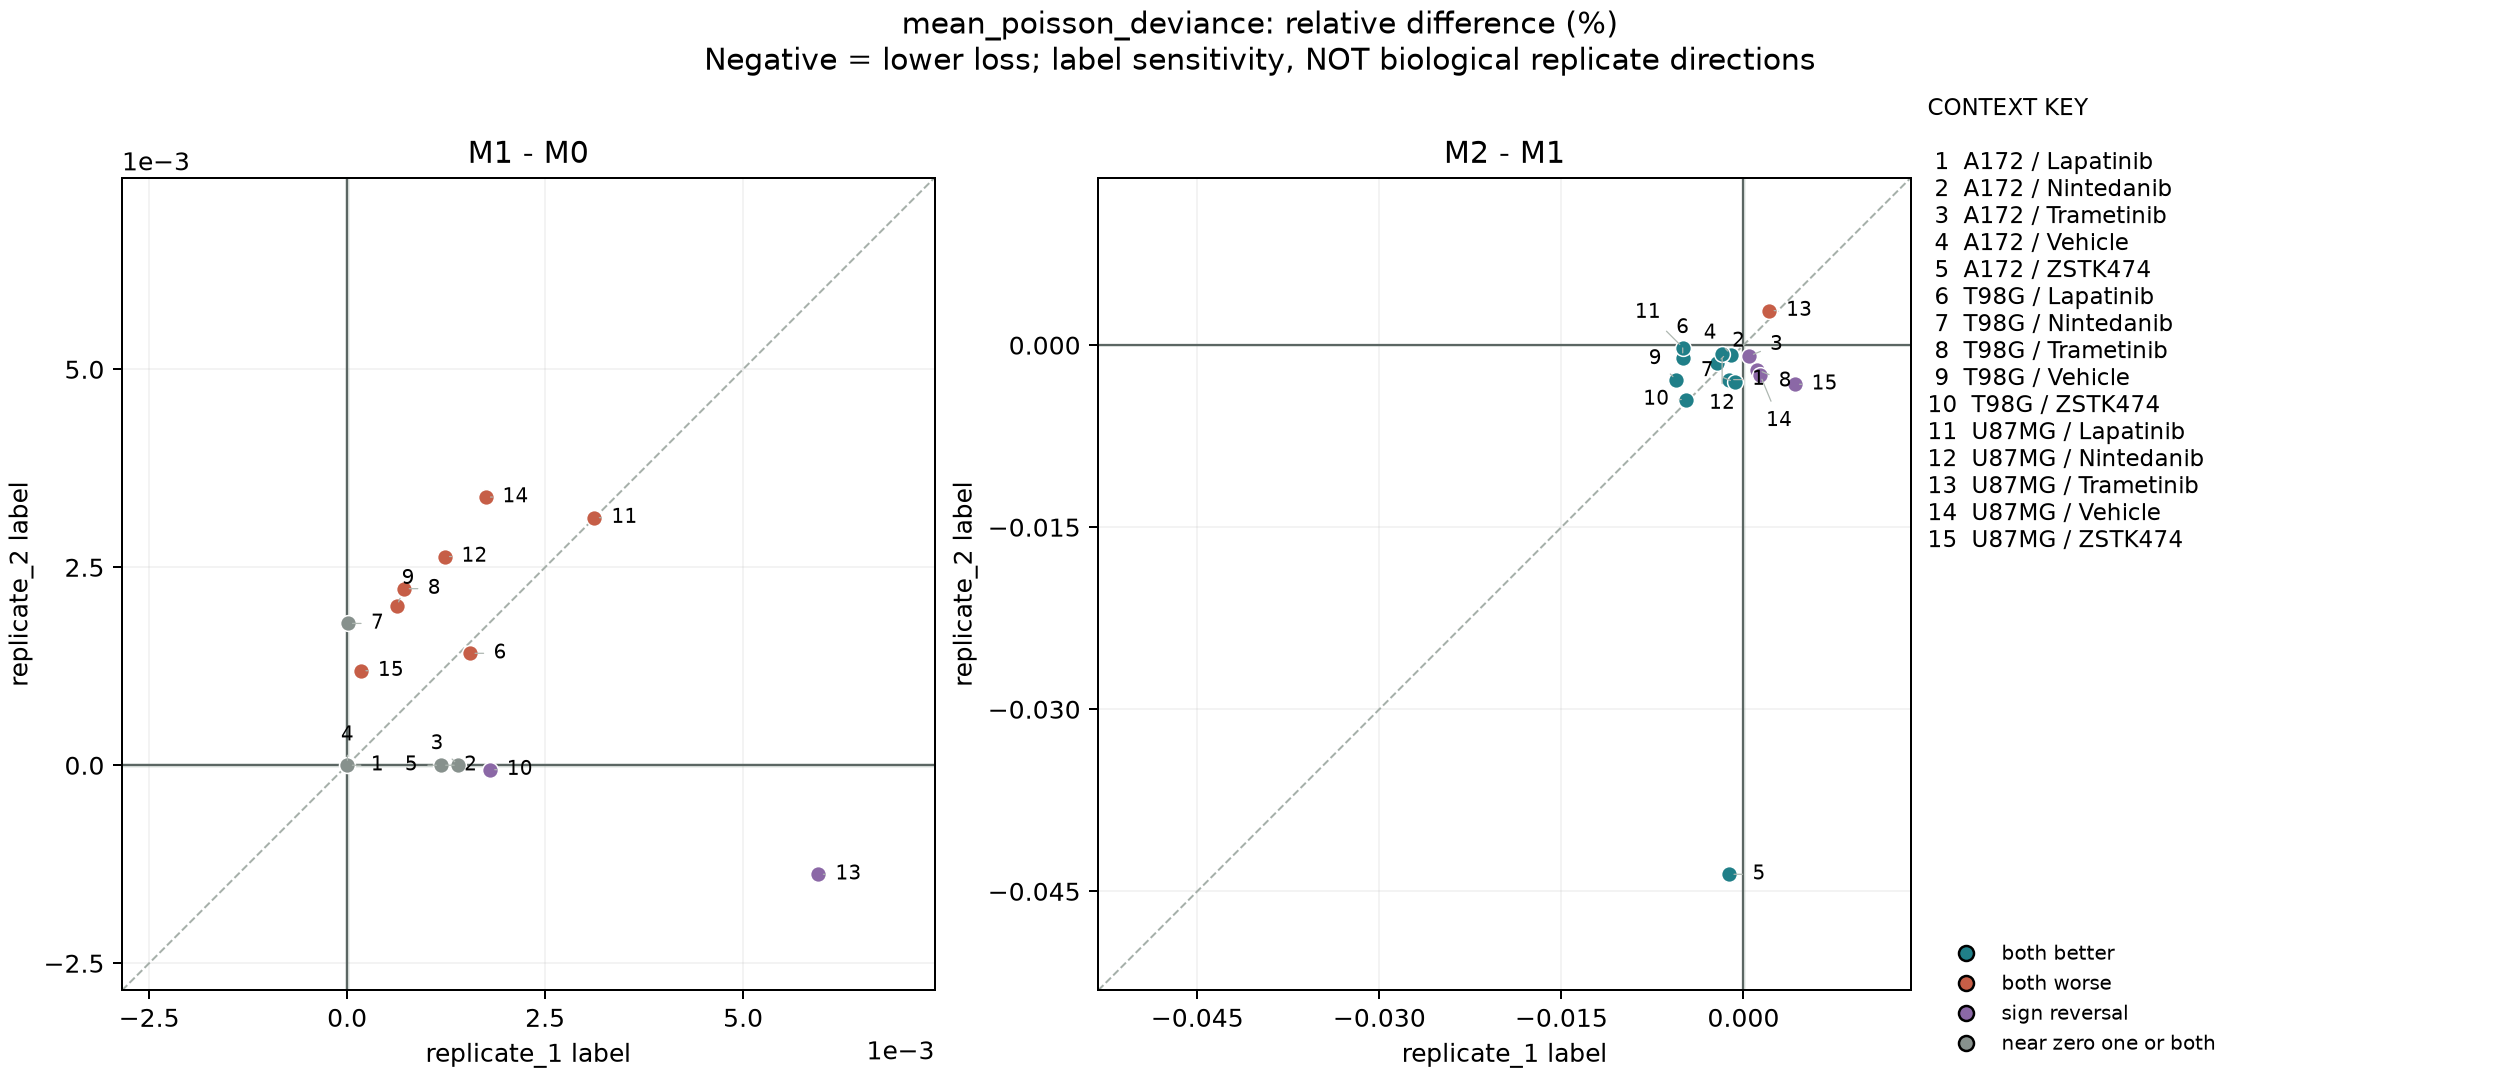

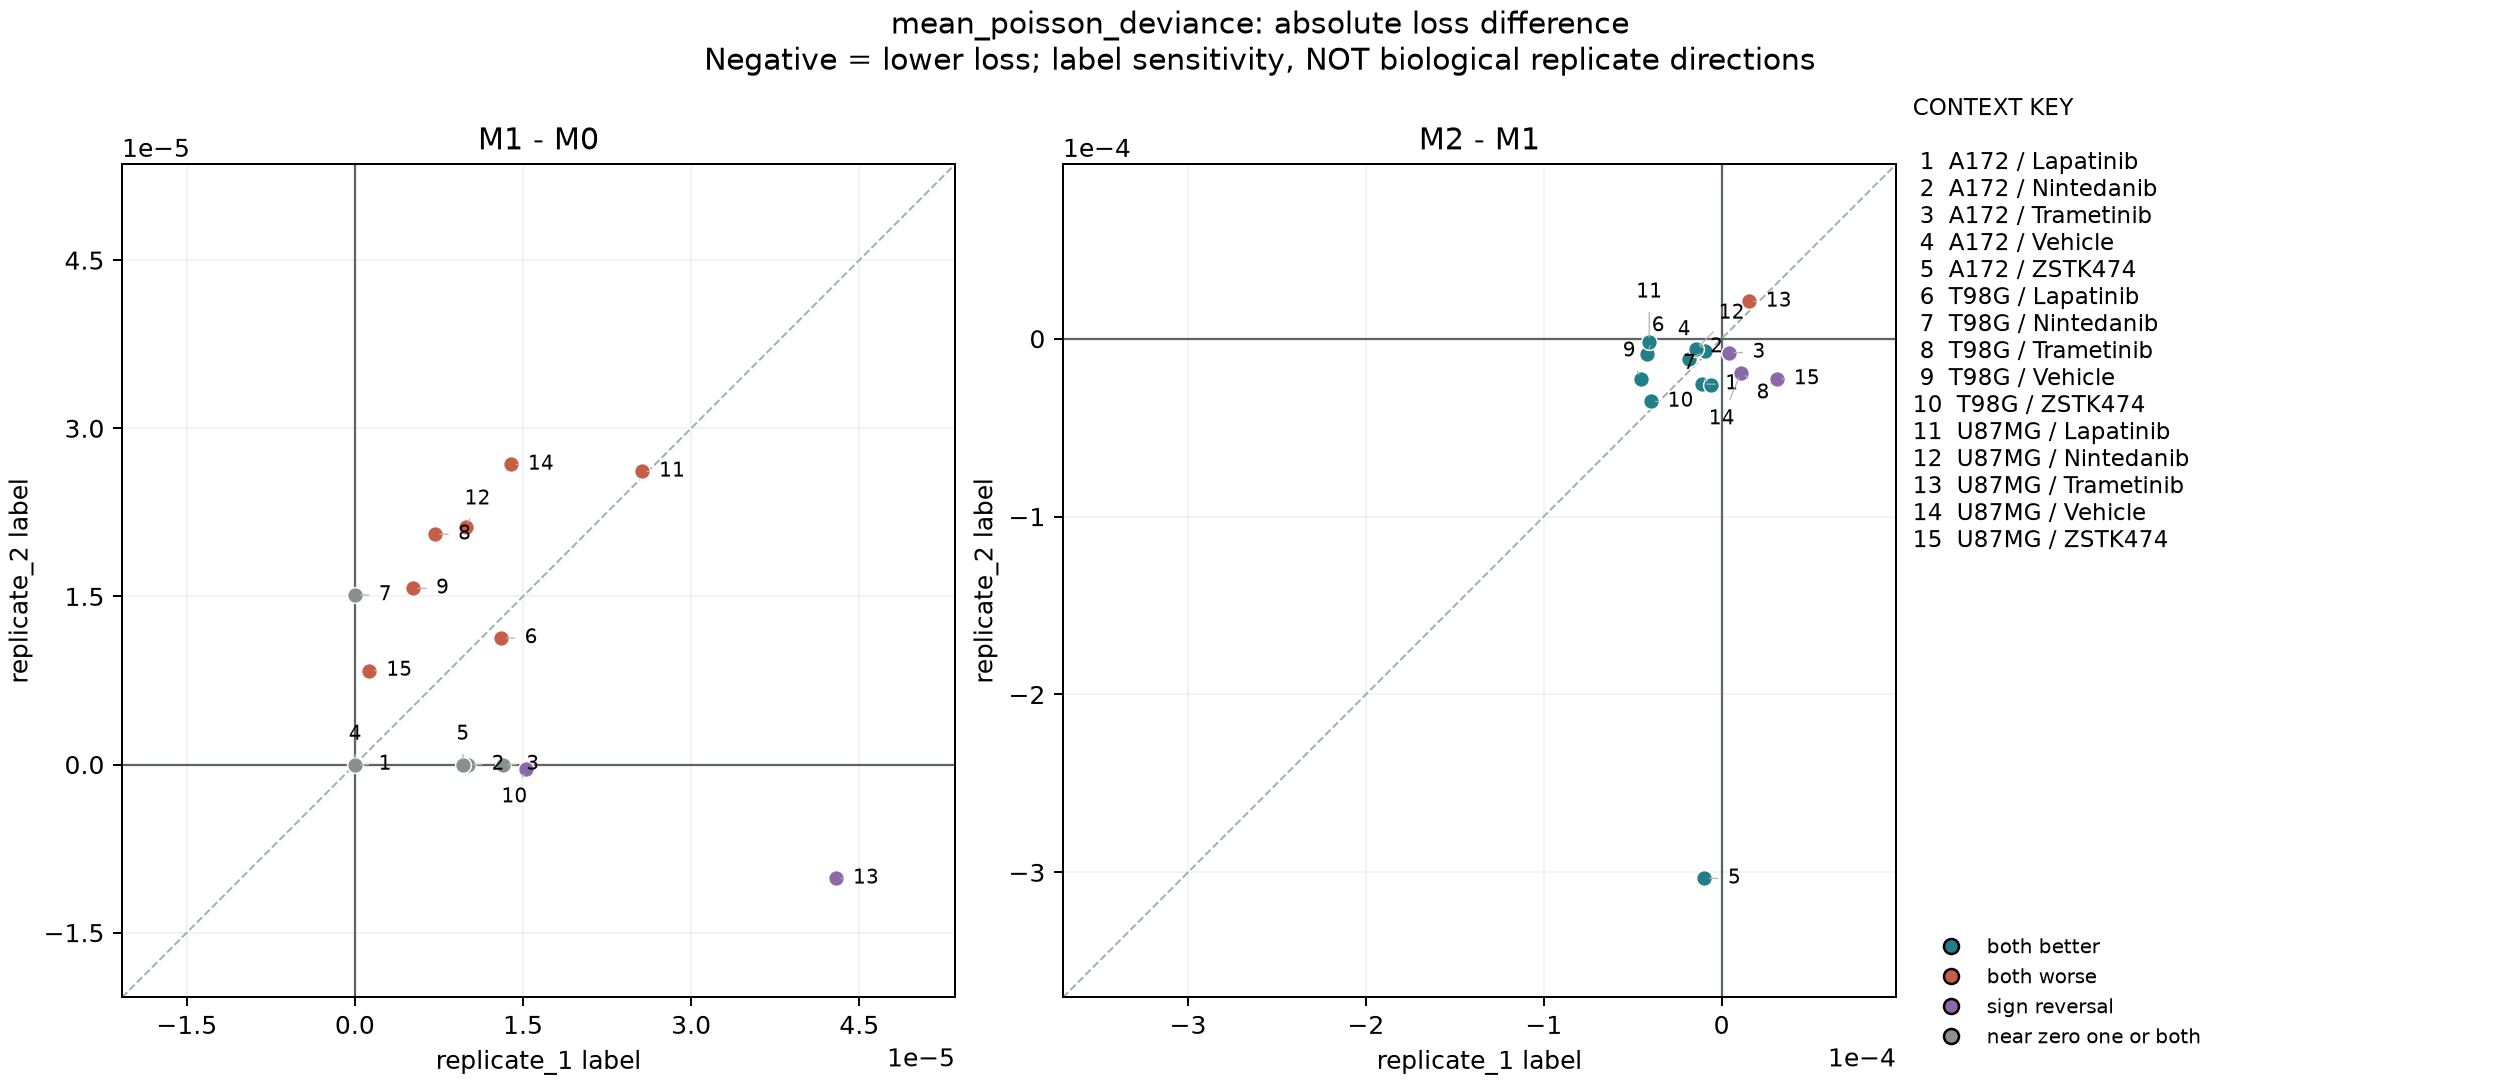

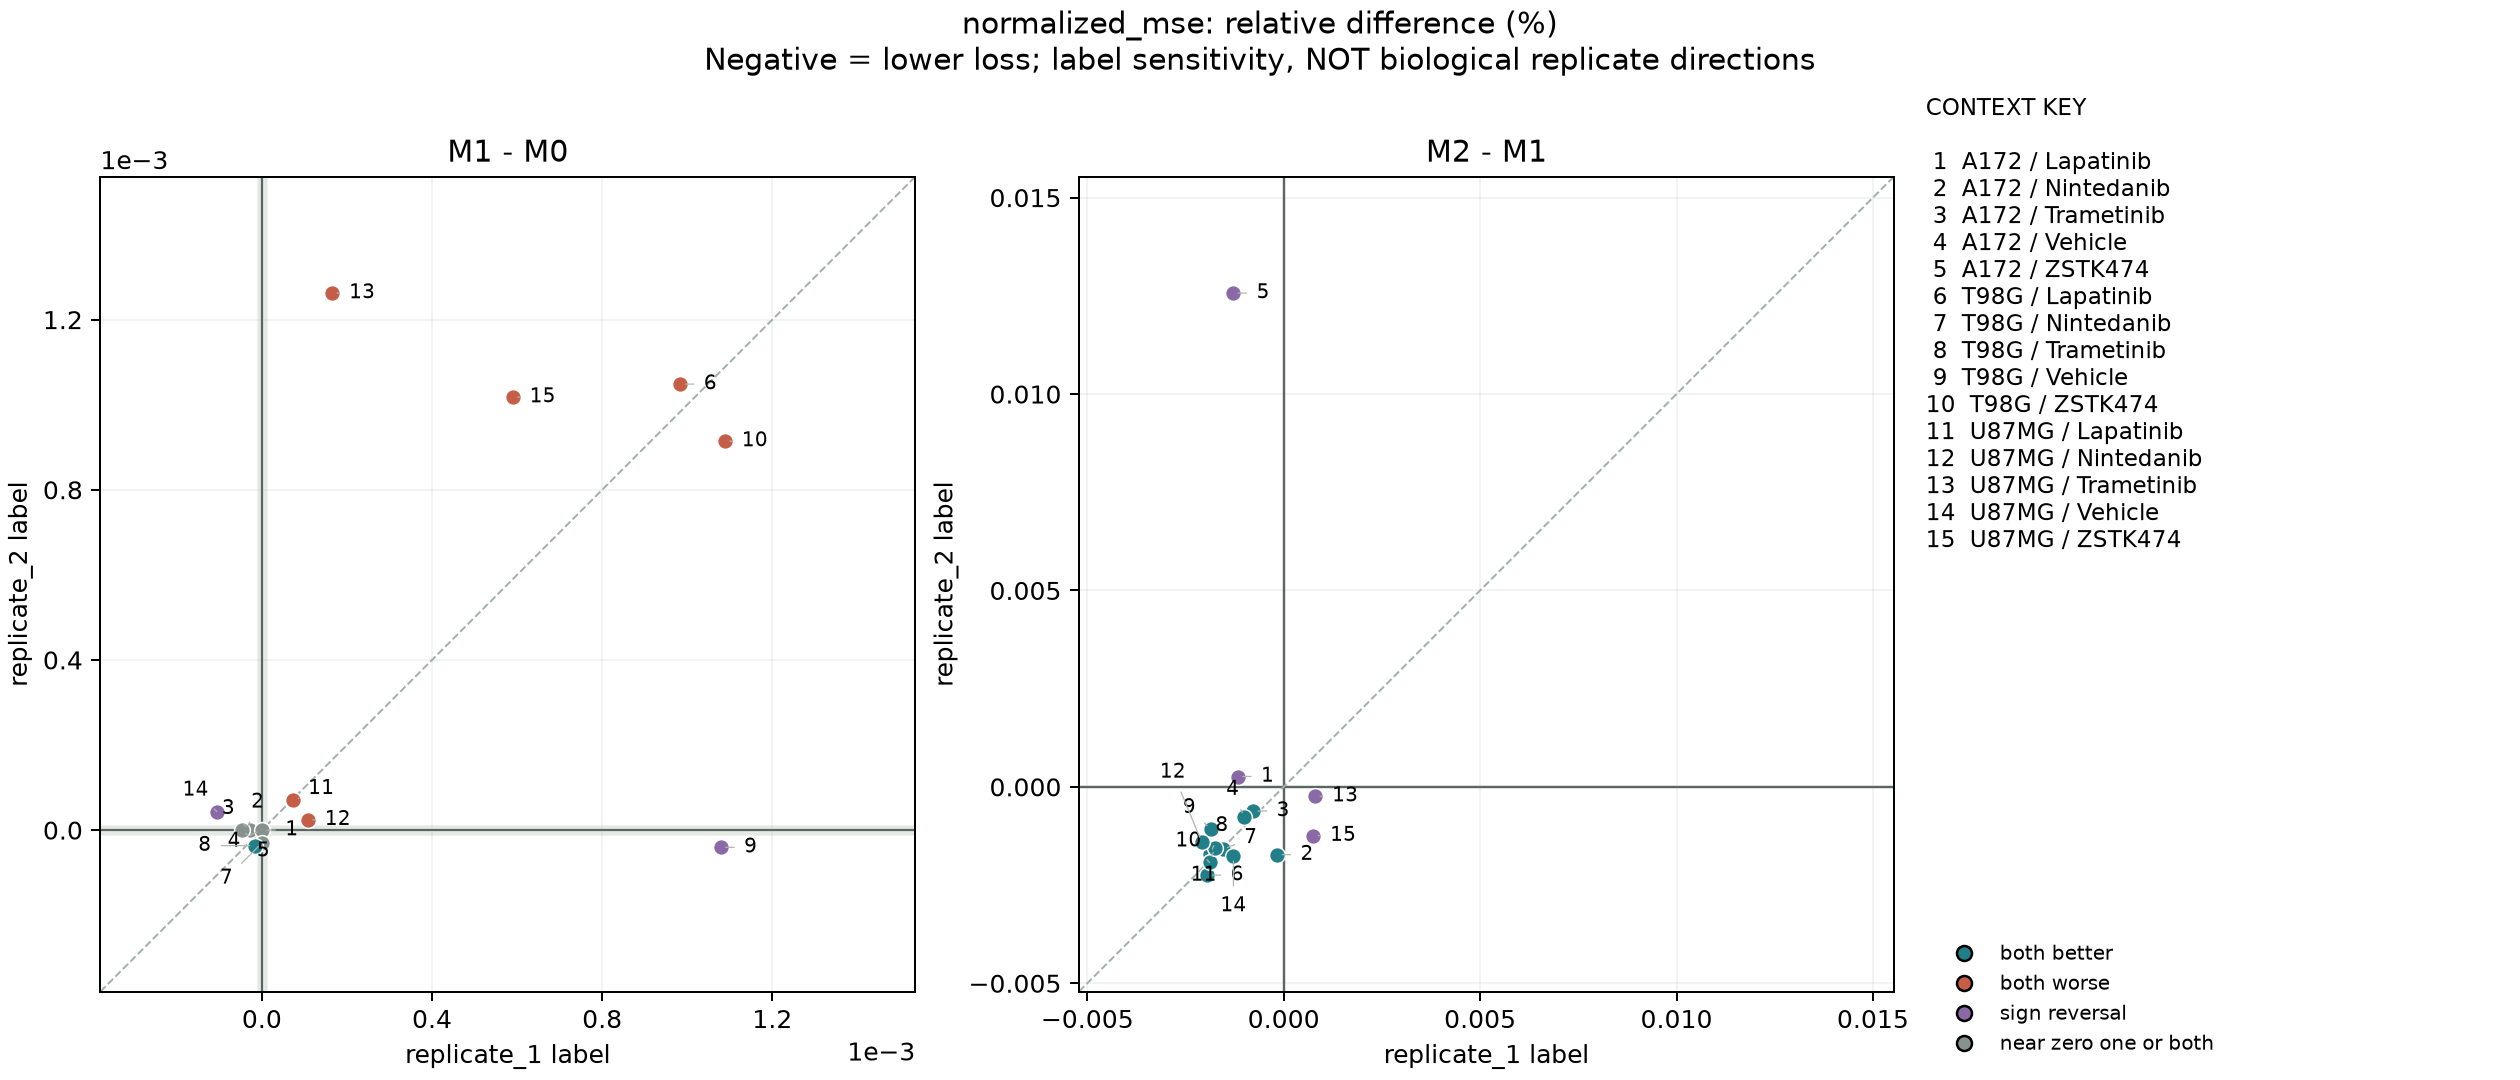

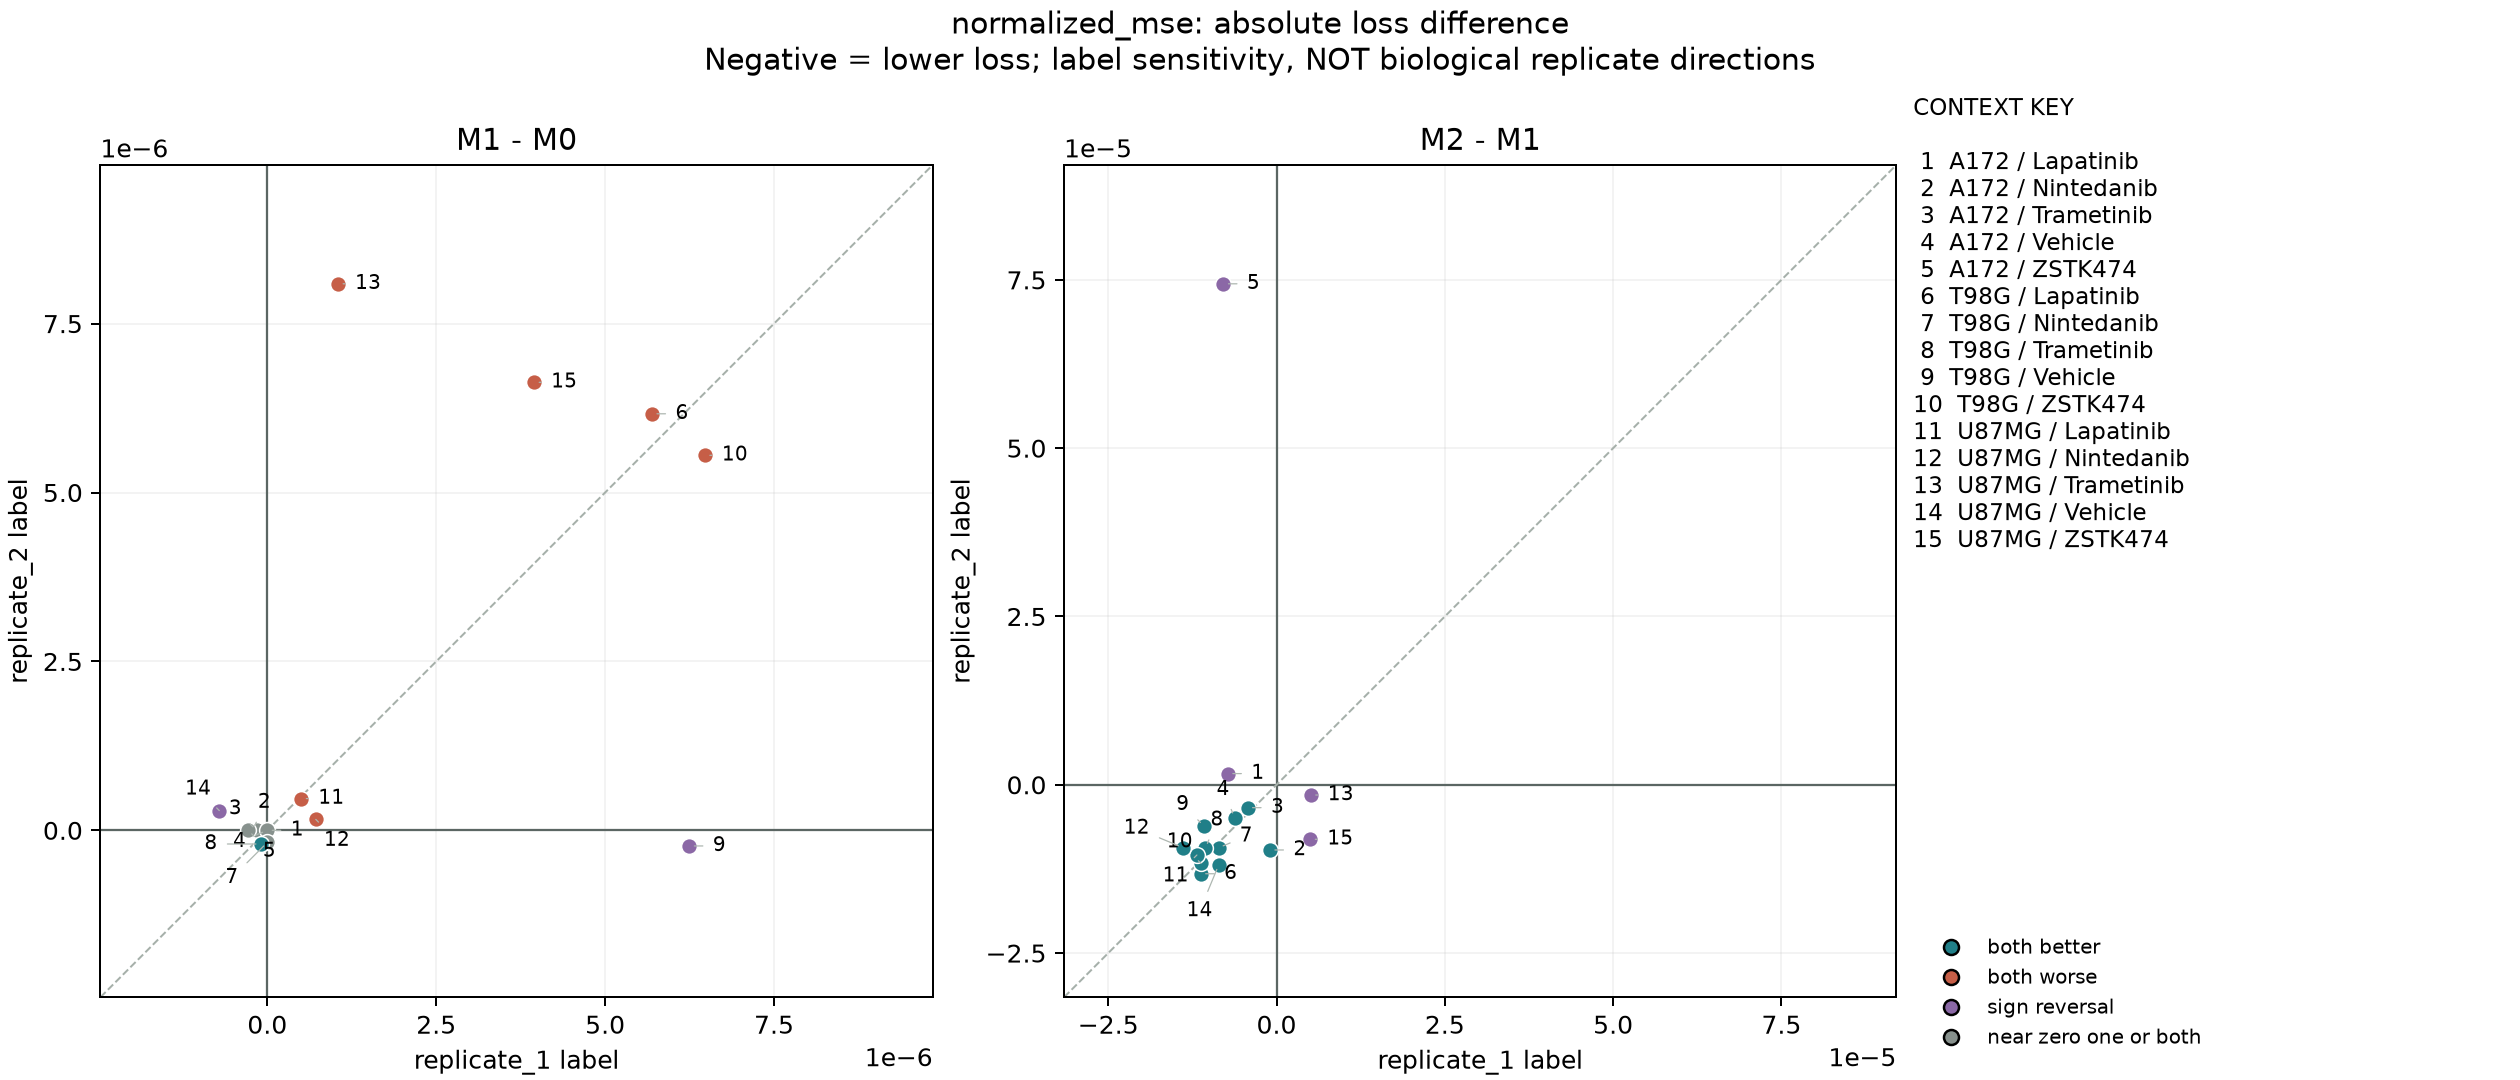

In [6]:
FIG_DIR=ROOT/"figures"/ANALYSIS_NAME
try:
    from IPython.display import display,Image
    for metric in cr.METRICS:
        for scale in ["percent","absolute"]:
            image_path=FIG_DIR/f"{metric}_{scale}_scatter.png"
            display(Image(filename=str(image_path)))
except ImportError:
    print("Please open the figure directory:",FIG_DIR)


In [7]:
BANDS=TABLES["near_zero_sensitivity"]
print(BANDS.loc[BANDS.metric.eq(PRIMARY)].to_string(index=False))


               metric comparison  near_zero_percent                 class  n_contexts
mean_poisson_deviance   adaptive            0.00000           both_better          10
mean_poisson_deviance   adaptive            0.00000            both_worse           1
mean_poisson_deviance   adaptive            0.00000         sign_reversal           4
mean_poisson_deviance   adaptive            0.00000 near_zero_one_or_both           0
mean_poisson_deviance      fixed            0.00000           both_better           0
mean_poisson_deviance      fixed            0.00000            both_worse           8
mean_poisson_deviance      fixed            0.00000         sign_reversal           2
mean_poisson_deviance      fixed            0.00000 near_zero_one_or_both           5
mean_poisson_deviance   adaptive            0.00001           both_better          10
mean_poisson_deviance   adaptive            0.00001            both_worse           1
mean_poisson_deviance   adaptive            0.00001   

In [8]:
print(TABLES["composition_differences"].to_string(index=False))
print(TABLES["composition_effect_associations"].to_string(index=False))
print("Composition Original Count Table:",ROOT/"results/summary"/ANALYSIS_NAME/"composition_counts.csv")


cell_line       drug     field               status  TV_all  JSD_all_bits  TV_known  JSD_known_bits
     A172    Vehicle  dose_raw METADATA_UNAVAILABLE     NaN           NaN       NaN             NaN
     A172    Vehicle sgRNA_raw METADATA_UNAVAILABLE     NaN           NaN       NaN             NaN
     A172  Lapatinib  dose_raw METADATA_UNAVAILABLE     NaN           NaN       NaN             NaN
     A172  Lapatinib sgRNA_raw METADATA_UNAVAILABLE     NaN           NaN       NaN             NaN
     A172 Nintedanib  dose_raw METADATA_UNAVAILABLE     NaN           NaN       NaN             NaN
     A172 Nintedanib sgRNA_raw METADATA_UNAVAILABLE     NaN           NaN       NaN             NaN
     A172 Trametinib  dose_raw METADATA_UNAVAILABLE     NaN           NaN       NaN             NaN
     A172 Trametinib sgRNA_raw METADATA_UNAVAILABLE     NaN           NaN       NaN             NaN
     A172    ZSTK474  dose_raw METADATA_UNAVAILABLE     NaN           NaN       NaN             NaN


In [9]:
print("Please return:",REVIEW_ZIP)
print("List of Figures:",FIG_DIR)
print("Analysis Configuration:",ROOT/"configs"/ANALYSIS_NAME/"analysis_contract.json")
print("biological directions：",SUMMARY["genuine_biological_direction_analysis"])


Please return: /home/featurize/work/biological_prior_validation/results/summary/task2_context_reproducibility_v1_review_bundle.zip
List of Figures: /home/featurize/work/biological_prior_validation/figures/task2_context_reproducibility_v1
Analysis Configuration: /home/featurize/work/biological_prior_validation/configs/task2_context_reproducibility_v1/analysis_contract.json
biological directions： BLOCKED_PENDING_PROVENANCE
